In [17]:
import os
import glob
import sys
import re
#import math
#import calendar
#from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import zipfile
import tempfile

#import matplotlib
#matplotlib.use("TkAgg")
#matplotlib.use('qtagg')
import matplotlib.pyplot as plt

#from scipy.optimize import curve_fit

from lidarpy.inversion import Klett
from lidarpy.molecular import AlphaBetaMolecular

In [18]:
#readting the .nc output file
file_path = "output/201705/201705_klett_annual.nc"
ds = xr.open_dataset(file_path)
#print(ds)
time = ds["time"].data
coef_slope = ds["coef_slope"].data
#print(alpha_aer)
print(time[:6])
print(coef_slope[:6])

['2017-05-03T19:00:00.000000000' '2017-05-03T21:00:00.000000000'
 '2017-05-04T03:00:00.000000000' '2017-05-07T12:00:00.000000000'
 '2017-05-07T13:00:00.000000000' '2017-05-07T15:00:00.000000000']
[[-9.81807980e+18  2.56590465e+04]
 [-8.19376733e+18  2.21950646e+04]
 [-1.05989562e+19  2.74602605e+04]
 [-2.42500864e+20  5.18709259e+05]
 [-5.27282261e+20  5.37732988e+05]
 [-6.52601391e+20  1.04918762e+06]]


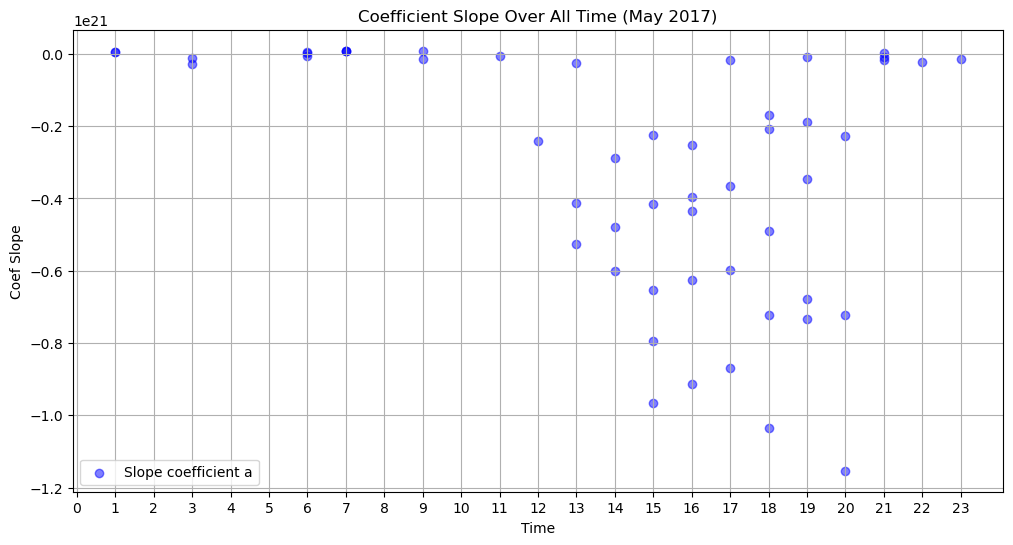

In [23]:
all_time = pd.to_datetime(time).hour > 0
coef_slope_all = coef_slope[all_time]
all_day = time[all_time]

hours_day = pd.to_datetime(all_day).hour
plt.figure(figsize=(12, 6))
plt.scatter(hours_day, coef_slope_all[:, 0], label='Slope coefficient a', color='blue', alpha=0.5)
plt.xlabel('Time')
plt.ylabel('Coef Slope')
plt.xticks(range(0, 24))
plt.title('Coefficient Slope Over All Time (May 2017)')
plt.legend()
plt.grid()
plt.show()

[[ 5.19996401e+18  6.09198571e+03]
 [ 1.52747670e+18  1.24994760e+04]
 [-1.80271989e+19  2.71280639e+04]
 [-7.22647564e+20  8.80908921e+05]
 [-2.27684064e+20  2.32426285e+05]
 [-1.15310744e+21  1.16944604e+06]]
['2017-05-15T01:00:00.000000000' '2017-05-15T21:00:00.000000000'
 '2017-05-18T21:00:00.000000000' '2017-05-19T20:00:00.000000000'
 '2017-05-21T20:00:00.000000000' '2017-05-22T20:00:00.000000000']


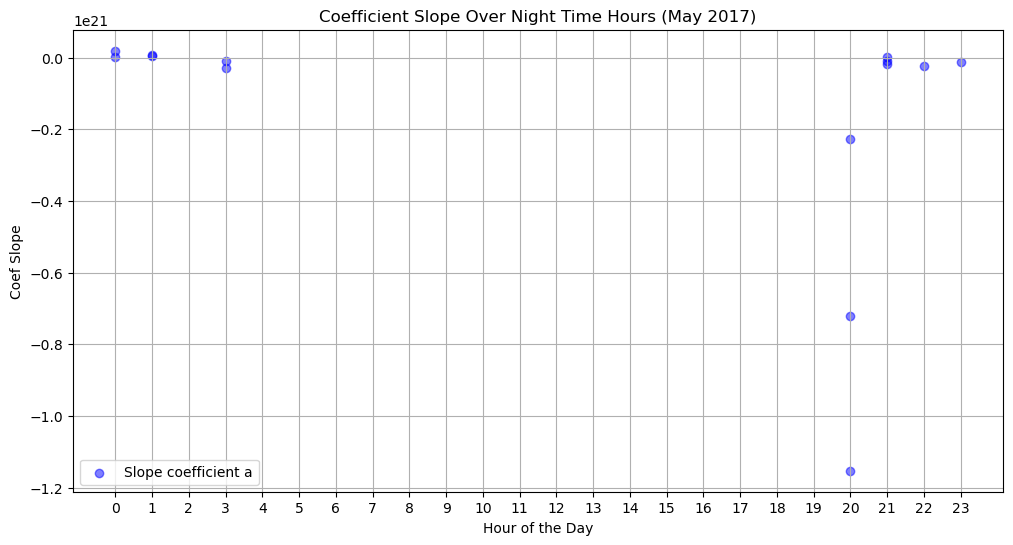

In [ ]:
# Make a filter of variable time to get only night time hours (from 20:00 to 04:00), time elements are in the format "YYYY-MM-DDTHH:MM:SS"
night_time = (pd.to_datetime(time).hour >= 20) | (pd.to_datetime(time).hour < 4)
coef_slope_night = coef_slope[night_time]
time_night = time[night_time]
print(coef_slope_night[-6:])
print(time_night[-6:])
# create array of only hour values from time_night
hours_night = pd.to_datetime(time_night).hour

plt.figure(figsize=(12, 6))
plt.scatter(hours_night, coef_slope_night[:, 0], label='Slope coefficient a', color='blue', alpha=0.5)
plt.xlabel('Hour of the Day')
plt.ylabel('Coef Slope')
plt.title('Coefficient Slope Over Night Time Hours (May 2017)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid()
plt.show()

[[ 5.19996401e+18  6.09198571e+03]
 [ 1.52747670e+18  1.24994760e+04]
 [-1.80271989e+19  2.71280639e+04]
 [-7.22647564e+20  8.80908921e+05]
 [-2.27684064e+20  2.32426285e+05]
 [-1.15310744e+21  1.16944604e+06]]
['2017-05-15T01:00:00.000000000' '2017-05-15T21:00:00.000000000'
 '2017-05-18T21:00:00.000000000' '2017-05-19T20:00:00.000000000'
 '2017-05-21T20:00:00.000000000' '2017-05-22T20:00:00.000000000']


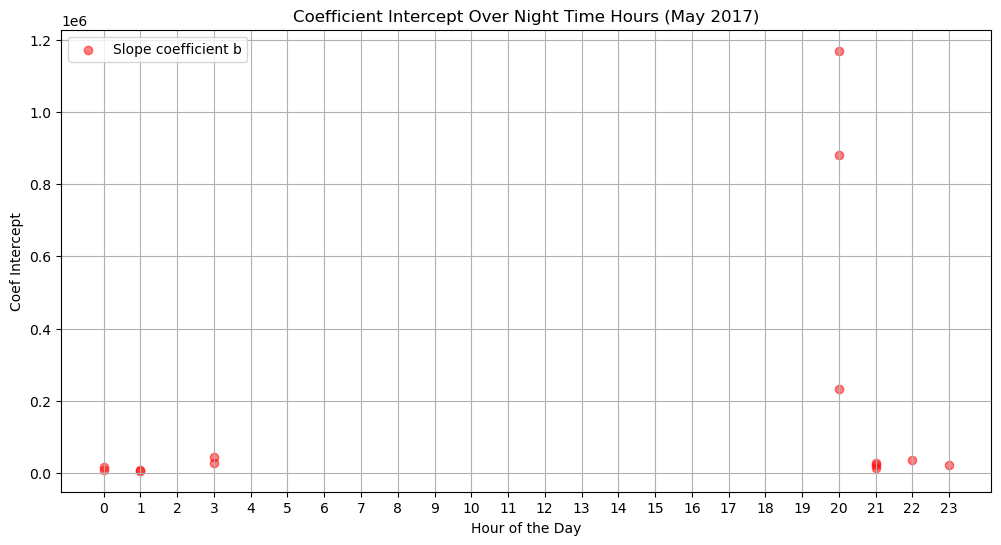

In [ ]:
# Make a filter of variable time to get only night time hours (from 20:00 to 04:00), time elements are in the format "YYYY-MM-DDTHH:MM:SS"
night_time = (pd.to_datetime(time).hour >= 20) | (pd.to_datetime(time).hour < 4)
coef_slope_night = coef_slope[night_time]
time_night = time[night_time]
print(coef_slope_night[-6:])
print(time_night[-6:])
# create array of only hour values from time_night
hours_night = pd.to_datetime(time_night).hour

plt.figure(figsize=(12, 6))
plt.scatter(hours_night, coef_slope_night[:, 1], label='Slope coefficient b', color='red', alpha=0.5)
plt.xlabel('Hour of the Day')
plt.ylabel('Coef Intercept')
plt.title('Coefficient Intercept Over Night Time Hours (May 2017)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid()
plt.show()